# Práctica 4 - Anatomía de un dataset de Machine Learning
Sesión 4 - El dataset

## Objetivos
Analizar un dataset desde el punto de vista de Machine Learning: muestras, variables, identificadores, características, target, \(X\), \(y\), tipos conceptuales, valores ausentes y distribuciones.

> El objetivo principal no es escribir mucho código, sino interpretar correctamente los datos.

## Contexto
Una plataforma de comercio electrónico dispone de información histórica sobre sus clientes. Trabajaremos con `clientes_ecommerce.csv`.

| Variable | Descripción |
|---|---|
| `cliente_id` | Identificador único |
| `edad` | Edad |
| `antiguedad_meses` | Meses desde el registro |
| `ingresos_anuales` | Ingresos anuales estimados |
| `gasto_mensual` | Gasto medio mensual |
| `num_compras` | Compras del último año |
| `devoluciones` | Devoluciones del último año |
| `dispositivo` | Dispositivo principal |
| `zona` | Zona de residencia |
| `nivel_fidelidad` | Bronce, Plata, Oro o Platino |
| `satisfaccion` | Valoración de 1 a 5 |
| `compra_proximo_mes` | Compra el mes siguiente: Sí/No |

Completa las celdas `# TODO` y responde en Markdown.

## Preparación

In [1]:
# TODO: importa NumPy, pandas y matplotlib.pyplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en df
df = pd.read_csv("clientes_ecommerce.csv")

## Parte 1 - Comprender el dataset
### Ejercicio 1 - Primera inspección
Muestra las primeras 10 filas.

In [2]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


\1
1. Una fila representa un cliente concreto y reúne los datos registrados sobre ese cliente.
2. Una columna representa una variable o característica, por ejemplo la edad, el gasto mensual o el dispositivo.
3. La unidad de observación es el cliente.
4. No. cliente_id es un identificador, no una característica de comportamiento. compra_proximo_mes es la variable objetivo que queremos predecir. Las demás columnas describen al cliente y podrían ser características, después de revisar su calidad y su disponibilidad en el momento de la predicción.

### Ejercicio 2 - Dimensiones
Obtén `df.shape`.

In [3]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

\1
- Número de muestras: 400.
- Número de columnas: 12.
- ¿Tenemos el mismo número de características? ¿Por qué? No. El dataset tiene 12 columnas, pero no todas son características predictoras: cliente_id es un identificador y compra_proximo_mes es el target. Por tanto, \(X\) contiene inicialmente 10 características.

## Parte 2 - Clasificación de variables
### Ejercicio 3 - Tipos almacenados

In [4]:
# TODO: consulta df.dtypes
df.dtypes

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object

### Ficha de variables
Clasifica cada variable como: Identificador, Numérica discreta, Numérica continua, Categórica nominal, Categórica ordinal o Target.

| Variable | dtype | Tipo conceptual | ¿Feature candidata? |
|---|---|---|---|
| cliente_id | | | |
| edad | | | |
| antiguedad_meses | | | |
| ingresos_anuales | | | |
| gasto_mensual | | | |
| num_compras | | | |
| devoluciones | | | |
| dispositivo | | | |
| zona | | | |
| nivel_fidelidad | | | |
| satisfaccion | | | |
| compra_proximo_mes | | | |

No clasifiques únicamente por `dtype`.

### Ejercicio 4 - `cliente_id`
Muestra sus primeros 10 valores.

In [5]:
# TODO: analiza cliente_id
print("Valores únicos:", df["cliente_id"].nunique())
print("Valores duplicados:", df["cliente_id"].duplicated().sum())
df["cliente_id"].describe()

Valores únicos: 400
Valores duplicados: 0


count      400.000000
mean     20200.500000
std        115.614301
min      20001.000000
25%      20100.750000
50%      20200.500000
75%      20300.250000
max      20400.000000
Name: cliente_id, dtype: float64

\1
1. cliente_id tiene dtype int64.
2. Técnicamente pandas lo almacena como número entero, pero conceptualmente no es una variable cuantitativa: es un identificador.
3. No tiene sentido calcular su media, porque el resultado no describe ninguna propiedad real de los clientes.
4. No lo incluiría inicialmente en \(X\).
5. Aunque sus valores sean números, solo sirven para distinguir clientes. El modelo podría aprender patrones arbitrarios relacionados con el identificador en lugar de relaciones útiles para predecir.

### Ejercicio 5 - `satisfaccion`
Muestra la frecuencia de sus valores ordenados.

In [6]:
# TODO: value_counts() + sort_index()
df["compra_proximo_mes"].value_counts().sort_index()

compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64

\1
1. Pandas la almacena como una columna numérica de tipo entero (int64).
2. No es simplemente numérica desde el punto de vista conceptual: representa una valoración.
3. Sí, existe un orden natural entre las respuestas, desde 1 (Muy insatisfecho) hasta 5 (Muy satisfecho).
4. Es una variable ordinal, porque sus categorías tienen un orden.
5. dtype indica cómo se almacena técnicamente el dato; el significado conceptual indica qué representa. Por eso puede tener dtype entero y, aun así, ser una escala ordinal.

## Parte 3 - Calidad de los datos
### Ejercicio 6 - Información estructural

In [7]:
# TODO: utiliza df.info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


\1
1. Hay 400 muestras.
2. Aparecen columnas int64, float64 y de tipo cadena (str).
3. No. Algunas columnas tienen menos de 400 valores no nulos.
4. Los ausentes están en antiguedad_meses, ingresos_anuales y gasto_mensual.
5. Faltan 12 valores en total: 5 en antiguedad_meses, 4 en ingresos_anuales y 3 en gasto_mensual.

### Ejercicio 7 - Valores ausentes
Calcula cantidad y porcentaje por columna.

In [8]:
# TODO: valores ausentes por columna
print(df.isna().sum())

# TODO: porcentaje de ausentes por columna
print((df.isna().mean() * 100).round(2))

cliente_id            0
edad                  0
antiguedad_meses      5
ingresos_anuales      4
gasto_mensual         3
num_compras           0
devoluciones          0
dispositivo           0
zona                  0
nivel_fidelidad       0
satisfaccion          0
compra_proximo_mes    0
dtype: int64
cliente_id            0.00
edad                  0.00
antiguedad_meses      1.25
ingresos_anuales      1.00
gasto_mensual         0.75
num_compras           0.00
devoluciones          0.00
dispositivo           0.00
zona                  0.00
nivel_fidelidad       0.00
satisfaccion          0.00
compra_proximo_mes    0.00
dtype: float64


### Reflexión
No es lo mismo. Si faltan 5 valores entre 50 muestras, falta el 10 % de los datos; si faltan 5 entre 100.000, solo falta el 0,005 %. El número absoluto es el mismo, pero el impacto sobre el conjunto es muy diferente. Los porcentajes permiten comparar la importancia de los valores ausentes entre columnas o datasets de tamaños distintos.

## Parte 4 - Construcción de X e y
Queremos predecir: ¿realizará el cliente una compra el próximo mes?

### Ejercicio 8 - Variable objetivo

In [9]:
# TODO: crea y
y = df["compra_proximo_mes"]

# TODO: muestra y.head() y y.shape
print(y.head())
print(y.shape)

0    No
1    No
2    Sí
3    Sí
4    No
Name: compra_proximo_mes, dtype: str
(400,)


\1
1. Cada elemento de \(y\) representa la etiqueta de un cliente: si comprará (Sí) o no comprará (No) el próximo mes.
2. Contiene 400 etiquetas, una por cada muestra.
3. El target no debe incluirse también en \(X\) porque es precisamente lo que queremos predecir. Si lo incluyéramos, el modelo tendría acceso a la respuesta correcta durante el entrenamiento y se produciría fuga de información.

### Ejercicio 9 - Construir \(X\)
Usa: `edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad`, `satisfaccion`.

No incluyas `cliente_id` ni `compra_proximo_mes`.

In [10]:
# TODO: crea X
X = df[[
    "edad", "antiguedad_meses", "ingresos_anuales", "gasto_mensual",
    "num_compras", "devoluciones", "dispositivo", "zona",
    "nivel_fidelidad", "satisfaccion"
]]

# TODO: muestra X.head() y X.shape
print(X.head())
print(X.shape)

   edad  antiguedad_meses  ingresos_anuales  gasto_mensual  num_compras  \
0    67             102.0           9000.00          60.73            7   
1    28              93.0          35683.86         131.74            6   
2    19              87.0          37152.19          55.33            8   
3    55              79.0          40158.29          24.33            7   
4    39               3.0          27317.06          88.78            5   

   devoluciones dispositivo   zona nivel_fidelidad  satisfaccion  
0             3       Móvil  Oeste             Oro             5  
1             1       Móvil   Este          Bronce             2  
2             1   Ordenador   Este           Plata             5  
3             0   Ordenador  Norte          Bronce             4  
4             0       Móvil    Sur          Bronce             4  
(400, 10)


### Ejercicio 10 - Dimensiones
Completa y explica:

- \(n =\)
- \(p =\)
- \(X.shape =\)
- \(y.shape =\)

## Parte 5 - ¿Está etiquetado?
### Ejercicio 11

Respuesta:
1. Sí. Tenemos \(X\), que contiene las variables descriptivas de los clientes.
2. Sí. Tenemos \(y\), que corresponde a compra_proximo_mes.
3. Sí, está etiquetado porque cada cliente tiene asociado un resultado conocido (Sí o No).
4. Sí. Podemos utilizarlo para aprendizaje supervisado separando las características \(X\) de la etiqueta \(y\).
5. Es un problema de clasificación, porque el objetivo es predecir una categoría.
6. Es binario, porque solo hay dos clases.
7. Las clases son Sí y No.

## Parte 6 - Distribuciones
### Ejercicio 12 - Variables categóricas
Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes` con frecuencias absolutas y relativas.

In [11]:
# TODO: value_counts() y value_counts(normalize=True) para las cuatro variables
for columna in ["dispositivo", "zona", "nivel_fidelidad", "compra_proximo_mes"]:
    print("\\n", columna)
    print(df[columna].value_counts())
    print(df[columna].value_counts(normalize=True))

\n dispositivo
dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        0.6050
Ordenador    0.3325
Tablet       0.0625
Name: proportion, dtype: float64
\n zona
zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
zona
Este      0.2225
Sur       0.2000
Norte     0.1975
Oeste     0.1900
Centro    0.1900
Name: proportion, dtype: float64
\n nivel_fidelidad
nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
nivel_fidelidad
Bronce     0.4050
Plata      0.2625
Oro        0.2075
Platino    0.1250
Name: proportion, dtype: float64
\n compra_proximo_mes
compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64
compra_proximo_mes
No    0.615
Sí    0.385
Name: proportion, dtype: float64


### Tabla resumen
| Variable | Categoría más frecuente | Frecuencia | Porcentaje |
|---|---|---:|---:|
| dispositivo | | | |
| zona | | | |
| nivel_fidelidad | | | |
| compra_proximo_mes | | | |

### Ejercicio 13 - Visualización del target
Crea un gráfico de barras con título y etiquetas.

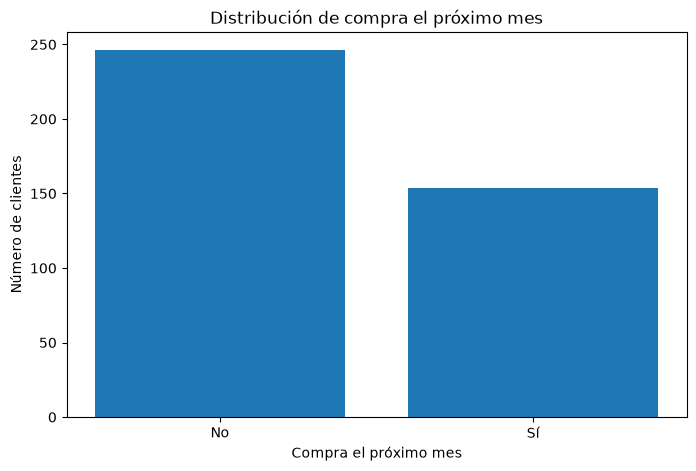

In [12]:
# TODO: gráfico de barras
conteos = df["compra_proximo_mes"].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(conteos.index, conteos.values)
plt.xlabel("Compra el próximo mes")
plt.ylabel("Número de clientes")
plt.title("Distribución de compra el próximo mes")
plt.show()

\1

Las clases no aparecen exactamente con la misma frecuencia. Hay 246 clientes que no compran (61,5 %) y 154 que sí compran (38,5 %). Por tanto, la clase No es más frecuente, aunque no existe un desequilibrio extremo.

## Parte 7 - Variables numéricas
### Ejercicio 14 - Estadística descriptiva
Analiza `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras` y `devoluciones`.

In [13]:
# TODO: describe() solo sobre las columnas indicadas
df[["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]].describe()

,edad,ingresos_anuales,gasto_mensual,num_compras,devoluciones
count,400.000000,396.000000,397.000000,400.000000,400.000000
mean,46.402500,36440.920379,69.089320,8.225000,1.225000
std,18.007809,14325.228166,39.023238,2.780955,1.136929
min,18.000000,9000.000000,5.770000,2.000000,0.000000
25%,33.000000,26034.092500,39.720000,6.000000,0.000000
50%,45.000000,36817.275000,61.170000,8.000000,1.000000
75%,59.000000,45969.032500,90.150000,10.000000,2.000000
max,195.000000,82925.370000,260.000000,17.000000,5.000000


\1

- edad: la mayoría de edades se encuentra dentro de un rango adulto, pero hay un valor claramente sospechoso de 195 años que debe revisarse.
- ingresos_anuales: es una variable numérica de cantidades monetarias; para describir su concentración y posible asimetría hay que consultar el histograma y las estadísticas descriptivas calculadas.
- gasto_mensual: los cuartiles observados en la práctica de análisis exploratorio son Q1 = 39,72, mediana = 61,17 y Q3 = 90,15. El 50 % central se encuentra entre 39,72 y 90,15.
- num_compras: representa un recuento de compras del último año; su distribución debe interpretarse a partir del histograma correspondiente.
- devoluciones: representa un recuento de devoluciones; al ser un recuento, sus valores son discretos y no negativos.

### Ejercicio 15 - Detectar algo sospechoso

Respuesta:
1. Sí, aparece un valor poco razonable.
2. Está en la variable edad.
3. El registro con cliente_id 20138 tiene una edad de 195 años, que no es una edad humana plausible.
4. No eliminaría inmediatamente toda la fila, porque las demás variables de ese cliente pueden ser válidas.
5. Comprobaría el registro original o la fuente de los datos. Si no se puede verificar la edad correcta, marcaría ese valor como ausente y lo trataría durante el preprocesamiento.

## Parte 8 - Distribuciones numéricas
### Ejercicio 16
Crea histogramas independientes de `edad`, `ingresos_anuales`, `gasto_mensual` y `num_compras`.

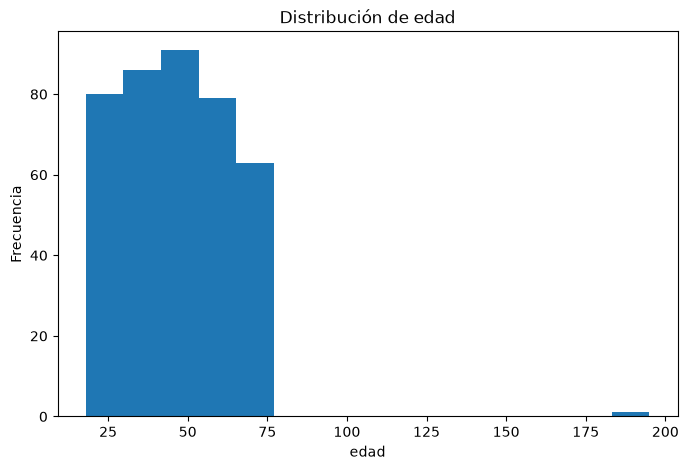

In [14]:
# TODO: histograma de edad
plt.figure(figsize=(8, 5))
plt.hist(df["edad"].dropna(), bins=15)
plt.xlabel("edad")
plt.ylabel("Frecuencia")
plt.title("Distribución de edad")
plt.show()

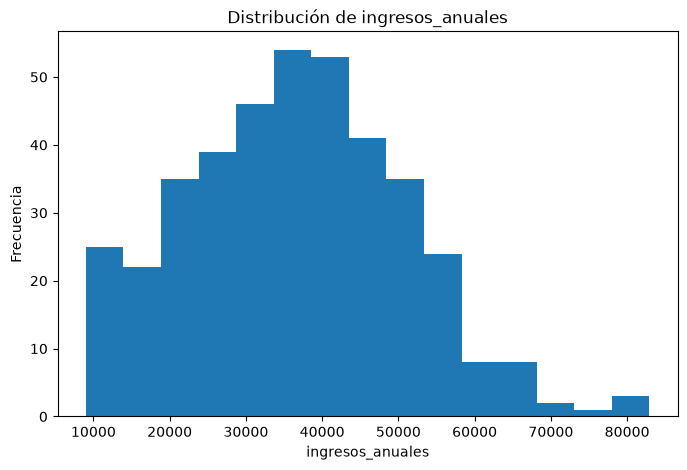

In [15]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(8, 5))
plt.hist(df["ingresos_anuales"].dropna(), bins=15)
plt.xlabel("ingresos_anuales")
plt.ylabel("Frecuencia")
plt.title("Distribución de ingresos_anuales")
plt.show()

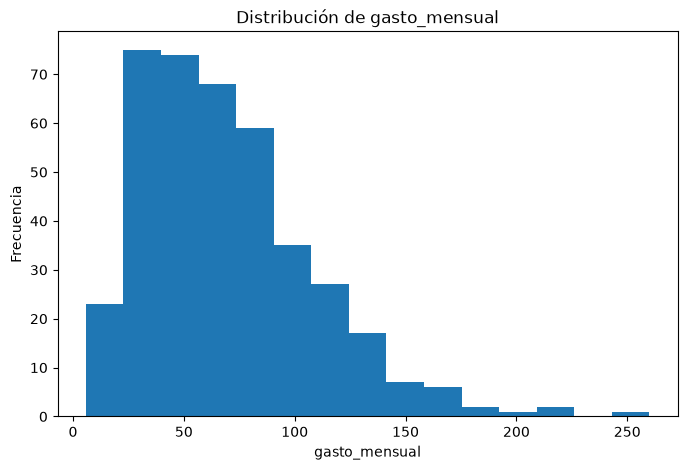

In [16]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(8, 5))
plt.hist(df["gasto_mensual"].dropna(), bins=15)
plt.xlabel("gasto_mensual")
plt.ylabel("Frecuencia")
plt.title("Distribución de gasto_mensual")
plt.show()

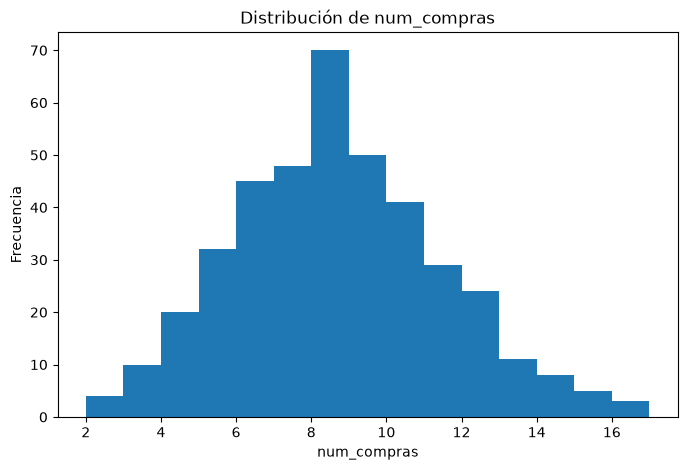

In [17]:
# TODO: histograma de num_compras
plt.figure(figsize=(8, 5))
plt.hist(df["num_compras"].dropna(), bins=15)
plt.xlabel("num_compras")
plt.ylabel("Frecuencia")
plt.title("Distribución de num_compras")
plt.show()

### Observaciones
- edad:
- ingresos_anuales:
- gasto_mensual:
- num_compras:

## Parte 9 - Un mismo dataset, diferentes problemas
### Ejercicio 17 - Problema A

> ¿Realizará el cliente una compra el próximo mes?

Respuesta:
- Target: compra_proximo_mes.
- ¿Existe \(y\)?: sí, porque el dataset contiene esa columna.
- Tipo de aprendizaje: supervisado, ya que tenemos ejemplos con la etiqueta conocida.
- Tipo de problema: clasificación.
- Binaria o multiclase: binaria, porque las clases son Sí y No.

### Ejercicio 18 - Problema B

Respuesta:
1. La variable objetivo sería gasto_proximo_mes.
2. Sería una variable cuantitativa numérica, normalmente continua, porque representa una cantidad monetaria.
3. Sí, sería aprendizaje supervisado si disponemos de ejemplos históricos con el gasto real del mes siguiente.
4. Sería un problema de regresión.
5. Porque queremos estimar una cantidad numérica, no elegir una categoría.

### Ejercicio 19 - Problema C

Respuesta:
1. No existe una etiqueta de grupo definida previamente.
2. No necesitamos \(y\) para descubrir los grupos.
3. Es aprendizaje no supervisado.
4. Podríamos utilizar una técnica de agrupamiento (*clustering*), por ejemplo K-Means.
5. Podríamos describir los grupos mediante variables como edad, antiguedad_meses, ingresos_anuales, gasto_mensual, num_compras, devoluciones, satisfaccion y nivel_fidelidad.

### Ejercicio 20 - ¿Una columna puede cambiar de papel?

Respuesta:
Una misma variable puede desempeñar papeles distintos dependiendo de qué queramos predecir. Si el objetivo es predecir `compra_proximo_mes`, esa columna es \(y\) y no debe incluirse en \(X\). En otro problema, por ejemplo si queremos predecir `gasto_proximo_mes`, `compra_proximo_mes` podría utilizarse como característica si ese dato ya está disponible en el momento de hacer la predicción. Por tanto, el papel de una columna depende del objetivo y de la información disponible al realizar la predicción.

### Ejercicio 21 - ¿Qué está mal aquí?

Respuesta:
No estoy de acuerdo con que todas las columnas de X sean automáticamente características adecuadas. Revisaría, como mínimo:
- cliente_id: es un identificador y no describe el comportamiento del cliente; normalmente debe excluirse.
- Calidad de los datos: hay valores ausentes y una edad sospechosa de 195 años que hay que revisar.
- Codificación: las variables categóricas necesitan una codificación adecuada; por ejemplo, dispositivo es nominal y nivel_fidelidad es ordinal.
- Fuga de información: comprobaría que ninguna variable contiene información que solo se conocería después del momento en el que se quiere predecir.
Separar \(X\) e \(y\) es el primer paso, pero no garantiza que todas las columnas restantes sean predictores adecuados.

## Parte 11 - Ficha técnica
### Ejercicio 22

```text
FICHA DEL DATASET
=================
Nombre: Clientes e-commerce
Número de muestras:
Número de columnas:
Unidad de observación:
Identificador:
Target:
Tipo de target:
Número de features candidatas:
Features numéricas:
Features categóricas nominales:
Features ordinales:
Datos etiquetados:
Valores ausentes:
Problema principal:
Tipo de aprendizaje:
Tipo de tarea:
```

## Parte 12 - Conclusiones
### Ejercicio 23

\1
El dataset contiene 400 clientes y 12 columnas.  
Cada fila representa un cliente y cada columna una variable registrada sobre él.  
Sin embargo, no todas las columnas son características predictoras.  
cliente_id funciona como identificador y compra_proximo_mes es el target.  
Por eso, inicialmente X contiene 10 características y y contiene 400 etiquetas.  
El problema de predecir la compra del próximo mes es de clasificación binaria.  
Las variables incluyen datos numéricos, categóricos nominales y una variable ordinal como nivel_fidelidad.  
La variable satisfaccion, aunque se almacena como entero, representa una escala ordinal de 1 a 5.  
Hay 12 valores ausentes: 5 en antiguedad_meses, 4 en ingresos_anuales y 3 en gasto_mensual.  
Además, aparece una edad de 195 años que debe revisarse porque parece un error de calidad.  
Las clases del target no están perfectamente equilibradas: 61,5 % son No y 38,5 % son Sí.  

# Ampliación opcional - El reto del analista
Mediante pandas, responde e interpreta:

1. ¿Qué nivel de fidelidad presenta mayor gasto mensual medio?
2. ¿El gasto histórico medio difiere entre quienes compran el mes siguiente y quienes no?
3. ¿Qué dispositivo tiene mayor número medio de compras?
4. ¿Cuál es la satisfacción media por nivel de fidelidad?
5. ¿Qué porcentaje de clientes de cada nivel compra el mes siguiente?

> Una asociación no demuestra causalidad.

In [18]:
# TODO: ampliación opcional
# Puedes investigar una variable adicional o una relación entre dos variables.

# Antes de entregar
- Completa todos los `TODO`.
- Responde las preguntas en Markdown.
- Añade títulos y etiquetas a los gráficos.
- Ejecuta el notebook completo desde el principio y comprueba que no hay errores.
- Justifica tus decisiones.

Nombre recomendado: `Practica_04_Apellido_Nombre.ipynb`